<a href="https://colab.research.google.com/github/vesakhaa/Statistika_Semester_3/blob/main/StatistikaJobsheet10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Rata-rata populasi (mu): 14819334.545454545
Std populasi (sigma): 15795573.488763059


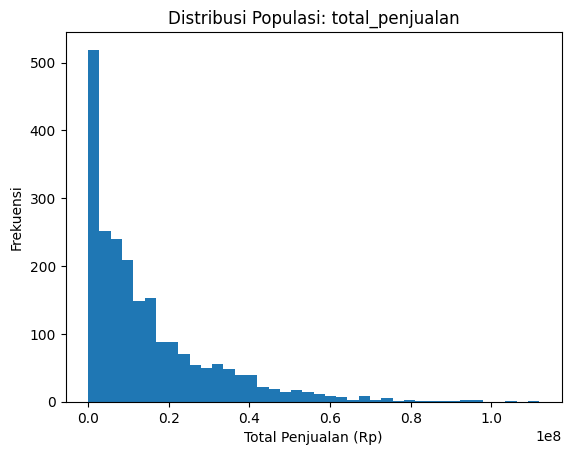

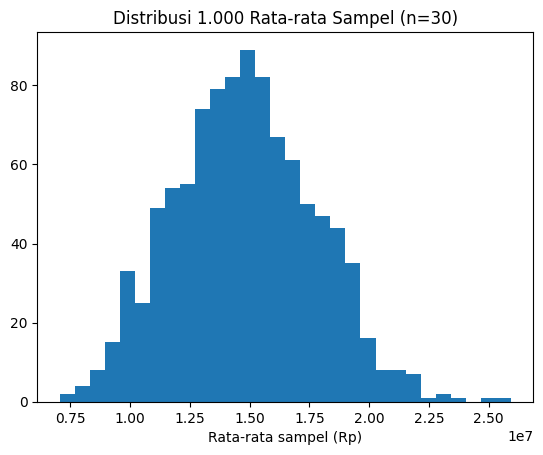

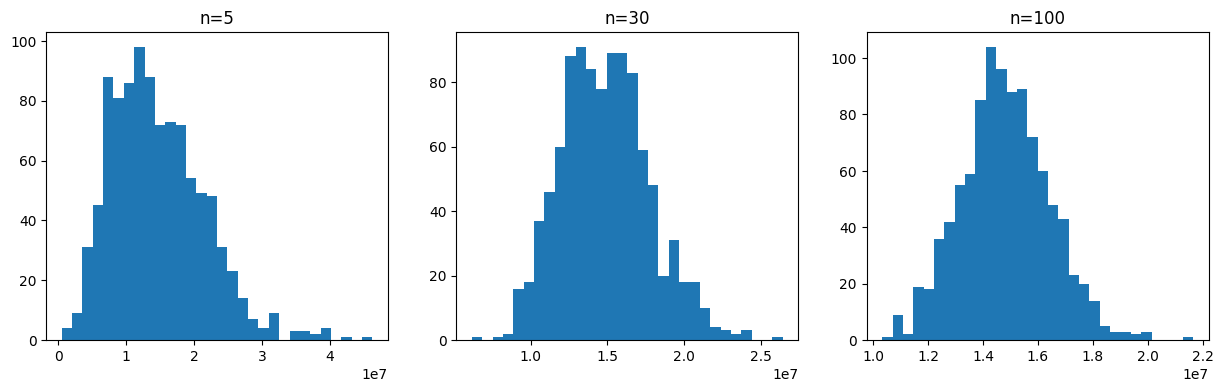

n=5: SE teoritis = 7,063,995  |  SE simulasi = 6,819,805
n=30: SE teoritis = 2,883,864  |  SE simulasi = 2,871,363
n=100: SE teoritis = 1,579,557  |  SE simulasi = 1,607,640


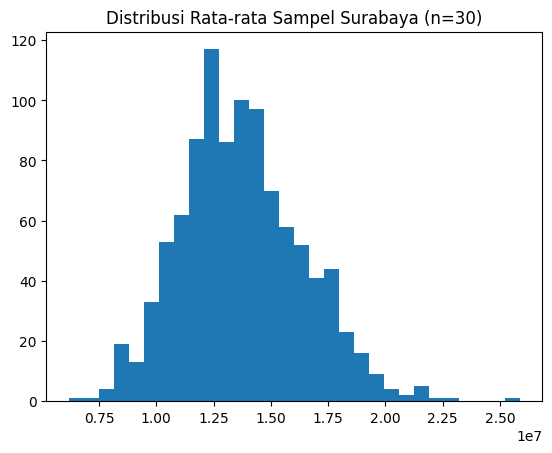

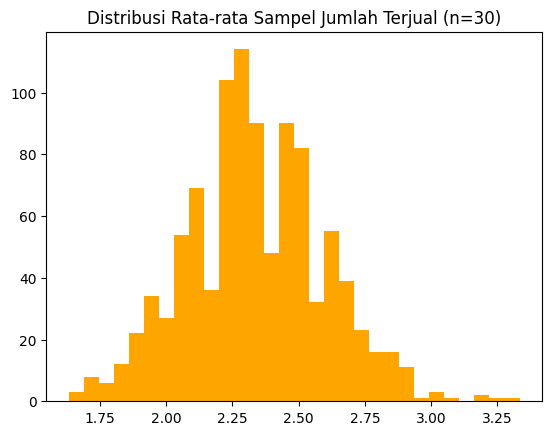

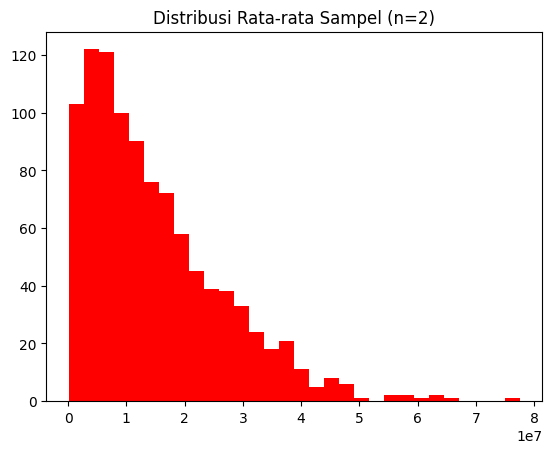

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('transaksi_elektronikprima.csv')
df.head()

populasi = df['total_penjualan']
print('Rata-rata populasi (mu):', populasi.mean())
print('Std populasi (sigma):', populasi.std())

plt.hist(populasi, bins=40)
plt.title('Distribusi Populasi: total_penjualan')
plt.xlabel('Total Penjualan (Rp)')
plt.ylabel('Frekuensi')
plt.show()

np.random.seed(42)
means_30 = []

for i in range(1000):
    sampel = populasi.sample(30)
    means_30.append(sampel.mean())

means_30 = np.array(means_30)

plt.hist(means_30, bins=30)
plt.title('Distribusi 1.000 Rata-rata Sampel (n=30)')
plt.xlabel('Rata-rata sampel (Rp)')
plt.show()

def simulasi_distribusi_sampling(data, n, reps=1000):
    means = []
    for i in range(reps):
        sampel = data.sample(n)
        means.append(sampel.mean())
    return np.array(means)

means_5   = simulasi_distribusi_sampling(populasi, 5)
means_30  = simulasi_distribusi_sampling(populasi, 30)
means_100 = simulasi_distribusi_sampling(populasi, 100)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(means_5, bins=30);   axes[0].set_title('n=5')
axes[1].hist(means_30, bins=30);  axes[1].set_title('n=30')
axes[2].hist(means_100, bins=30); axes[2].set_title('n=100')
plt.show()

for n_val, means in [(5, means_5), (30, means_30), (100, means_100)]:
    se_teoritis = populasi.std() / np.sqrt(n_val)
    se_simulasi = means.std()
    print(f'n={n_val}: SE teoritis = {se_teoritis:,.0f}  |  SE simulasi = {se_simulasi:,.0f}')

# Filter populasi khusus Surabaya
populasi_sby = df[df['cabang'] == 'Surabaya']['total_penjualan']

# Simulasi (n=30)
means_30_sby = simulasi_distribusi_sampling(populasi_sby, 30)

plt.hist(means_30_sby, bins=30)
plt.title('Distribusi Rata-rata Sampel Surabaya (n=30)')
plt.show()

# Ganti kolom ke jumlah_terjual
populasi_jt = df['jumlah_terjual']

# Simulasi (n=30)
means_30_jt = simulasi_distribusi_sampling(populasi_jt, 30)

plt.hist(means_30_jt, bins=30, color='orange')
plt.title('Distribusi Rata-rata Sampel Jumlah Terjual (n=30)')
plt.show()

# Simulasi sampel super kecil (n=2)
means_2 = simulasi_distribusi_sampling(populasi, 2)

plt.hist(means_2, bins=30, color='red')
plt.title('Distribusi Rata-rata Sampel (n=2)')
plt.show()